In [2]:
pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [4]:
import pandas as pd

df = pd.read_csv("medical_examination.csv")

print(df.head())

   id    age  sex  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  \
0   0  18393    2     168    62.0    110     80            1     1      0   
1   1  20228    1     156    85.0    140     90            3     1      0   
2   2  18857    1     165    64.0    130     70            3     1      0   
3   3  17623    2     169    82.0    150    100            1     1      0   
4   4  17474    1     156    56.0    100     60            1     1      0   

   alco  active  cardio  
0     0       1       0  
1     0       1       1  
2     0       0       1  
3     0       1       1  
4     0       0       0  


In [6]:
df.shape

(70000, 13)

In [7]:
df.columns

Index(['id', 'age', 'sex', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol',
       'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   sex          70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [10]:
df.describe()

,id,age,sex,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349843,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.477253,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,3.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [12]:
df["bmi"] = df["weight"] / ((df["height"] / 100) ** 2)

In [13]:
df[["height", "weight", "bmi"]].head()

,height,weight,bmi
0,168,62.0,21.967120
1,156,85.0,34.927679
2,165,64.0,23.507805
3,169,82.0,28.710479
4,156,56.0,23.011177


In [14]:
df["overweight"] = (df["bmi"] > 25).astype(int)

In [15]:
df[["bmi", "overweight"]].head(10)

,bmi,overweight
0,21.967120,0
1,34.927679,1
2,23.507805,0
3,28.710479,1
4,23.011177,0
5,29.384676,1
6,37.729725,1
7,29.983588,1
8,28.440955,1
9,25.282570,1


In [16]:
df["bmi"] > 25

0        False
1         True
2        False
3         True
4        False
         ...  
69995     True
69996     True
69997     True
69998     True
69999    False
Name: bmi, Length: 70000, dtype: bool

In [17]:
.astype(int)

SyntaxError: invalid syntax (4146531520.py, line 1)

In [18]:
df["overweight"].value_counts()

overweight
1    43546
0    26454
Name: count, dtype: int64

In [19]:
df.drop("bmi", axis=1, inplace=True)

In [20]:
df.head()

,id,age,sex,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,overweight
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1,0
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0,0


In [21]:
# Calculate BMI
df["bmi"] = df["weight"] / ((df["height"] / 100) ** 2)

# Create overweight column
df["overweight"] = (df["bmi"] > 25).astype(int)

# Check result
print(df[["height", "weight", "bmi", "overweight"]].head(10))

# Check counts
print(df["overweight"].value_counts())

# Remove temporary BMI column
df.drop("bmi", axis=1, inplace=True)

   height  weight        bmi  overweight
0     168    62.0  21.967120           0
1     156    85.0  34.927679           1
2     165    64.0  23.507805           0
3     169    82.0  28.710479           1
4     156    56.0  23.011177           0
5     151    67.0  29.384676           1
6     157    93.0  37.729725           1
7     178    95.0  29.983588           1
8     158    71.0  28.440955           1
9     164    68.0  25.282570           1
overweight
1    43546
0    26454
Name: count, dtype: int64


In [24]:
df["cholesterol"].value_counts()


cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64

In [25]:
df["gluc"].value_counts()

gluc
1    59479
3     5331
2     5190
Name: count, dtype: int64

In [26]:
df["cholesterol"] = (df["cholesterol"] > 1).astype(int)

In [27]:
df["cholesterol"].value_counts()

cholesterol
0    52385
1    17615
Name: count, dtype: int64

In [28]:
df["gluc"] = (df["gluc"] > 1).astype(int)

In [29]:
df["gluc"].value_counts()

gluc
0    59479
1    10521
Name: count, dtype: int64

In [30]:
df[["cholesterol", "gluc"]].head(10)

,cholesterol,gluc
0,0,0
1,1,0
2,1,0
3,0,0
4,0,0
5,1,1
6,1,0
7,1,1
8,0,0
9,0,0


In [31]:
(df["cholesterol"] > 1)

0        False
1        False
2        False
3        False
4        False
         ...  
69995    False
69996    False
69997    False
69998    False
69999    False
Name: cholesterol, Length: 70000, dtype: bool

In [32]:
.astype(int)

SyntaxError: invalid syntax (4146531520.py, line 1)

In [33]:
# Normalize cholesterol
df["cholesterol"] = (df["cholesterol"] > 1).astype(int)

# Normalize glucose
df["gluc"] = (df["gluc"] > 1).astype(int)

# Check the result
print(df[["cholesterol", "gluc"]].head(10))

   cholesterol  gluc
0            0     0
1            0     0
2            0     0
3            0     0
4            0     0
5            0     0
6            0     0
7            0     0
8            0     0
9            0     0


In [35]:
df[[
    "cardio",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "overweight"
]].head()

,cardio,cholesterol,gluc,smoke,alco,active,overweight
0,0,0,0,0,0,1,0
1,1,0,0,0,0,1,1
2,1,0,0,0,0,0,0
3,1,0,0,0,0,1,1
4,0,0,0,0,0,0,0


In [36]:
df_cat = pd.melt(
    df,
    id_vars=["cardio"],
    value_vars=[
        "cholesterol",
        "gluc",
        "smoke",
        "alco",
        "active",
        "overweight"
    ]
)

In [37]:
df_cat.head(15)

,cardio,variable,value
0,0,cholesterol,0
1,1,cholesterol,0
2,1,cholesterol,0
3,1,cholesterol,0
4,0,cholesterol,0
5,0,cholesterol,0
6,0,cholesterol,0
7,1,cholesterol,0
8,0,cholesterol,0
9,0,cholesterol,0


In [38]:
df_cat.shape

(420000, 3)

In [39]:
df_cat = (
    df_cat
    .groupby(["cardio", "variable", "value"])
    .size()
    .reset_index(name="total")
)

In [40]:
df_cat.head(20)

,cardio,variable,value,total
0,0,active,0,6378
1,0,active,1,28643
2,0,alco,0,33080
3,0,alco,1,1941
4,0,cholesterol,0,35021
5,0,gluc,0,35021
6,0,overweight,0,15915
7,0,overweight,1,19106
8,0,smoke,0,31781
9,0,smoke,1,3240


In [41]:
# Convert data from wide format to long format

df_cat = pd.melt(
    df,
    id_vars=["cardio"],
    value_vars=[
        "cholesterol",
        "gluc",
        "smoke",
        "alco",
        "active",
        "overweight"
    ]
)

# Count each combination
df_cat = (
    df_cat
    .groupby(["cardio", "variable", "value"])
    .size()
    .reset_index(name="total")
)

# Check result
df_cat.head(20)

,cardio,variable,value,total
0,0,active,0,6378
1,0,active,1,28643
2,0,alco,0,33080
3,0,alco,1,1941
4,0,cholesterol,0,35021
5,0,gluc,0,35021
6,0,overweight,0,15915
7,0,overweight,1,19106
8,0,smoke,0,31781
9,0,smoke,1,3240


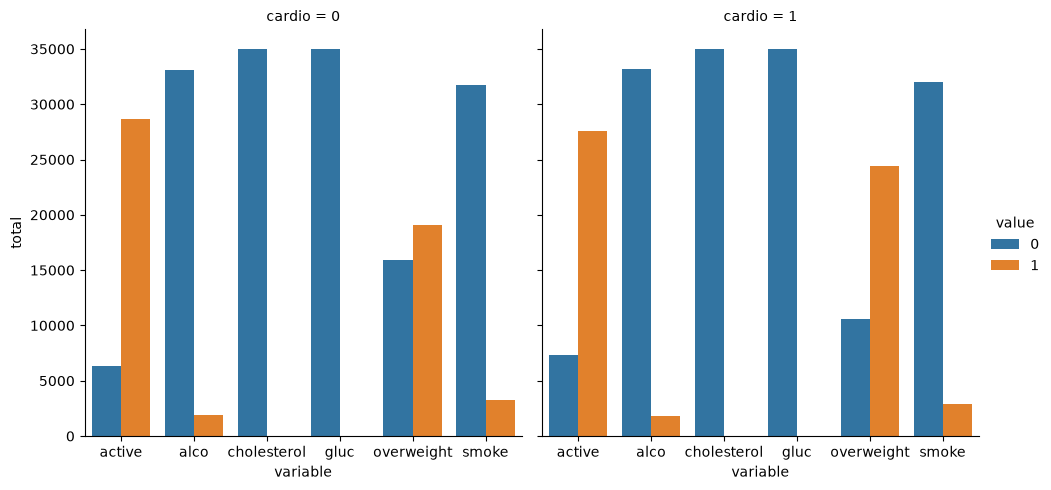

In [42]:
fig = sns.catplot(
    x="variable",
    y="total",
    hue="value",
    col="cardio",
    data=df_cat,
    kind="bar"
)

In [44]:
kind="bar"

In [45]:
fig.savefig("catplot.png")

In [46]:
plt.show()


In [48]:
df_heat = df[df["ap_lo"] <= df["ap_hi"]]

In [49]:
df_heat.shape

(68766, 14)

In [50]:
(df_heat["ap_lo"] > df_heat["ap_hi"]).sum()

np.int64(0)

In [51]:
df_heat["height"].quantile(0.025)

np.float64(150.0)

In [52]:
df_heat["height"].quantile(0.975)

np.float64(180.0)

In [53]:
df_heat = df_heat[
    (df_heat["height"] >= df_heat["height"].quantile(0.025)) &
    (df_heat["height"] <= df_heat["height"].quantile(0.975))
]

In [54]:
df_heat["weight"].quantile(0.025)

np.float64(52.0)

In [55]:
df_heat["weight"].quantile(0.975)

np.float64(106.0)

In [56]:
df_heat = df_heat[
    (df_heat["weight"] >= df_heat["weight"].quantile(0.025)) &
    (df_heat["weight"] <= df_heat["weight"].quantile(0.975))
]

In [57]:
# Remove incorrect blood pressure records
df_heat = df[df["ap_lo"] <= df["ap_hi"]]

# Remove extreme height values
df_heat = df_heat[
    (df_heat["height"] >= df_heat["height"].quantile(0.025)) &
    (df_heat["height"] <= df_heat["height"].quantile(0.975))
]

# Remove extreme weight values
df_heat = df_heat[
    (df_heat["weight"] >= df_heat["weight"].quantile(0.025)) &
    (df_heat["weight"] <= df_heat["weight"].quantile(0.975))
]

# Check final number of rows
print(df_heat.shape)

(62784, 14)


In [58]:
(df_heat["ap_lo"] > df_heat["ap_hi"]).sum()

np.int64(0)

In [59]:
corr = df_heat.corr()

In [60]:
np.triu()

TypeError: triu() missing 1 required positional argument: 'm'

In [61]:
corr = df_heat.corr()

In [62]:
corr

,id,age,sex,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,overweight
id,1.000000,0.002623,0.003799,0.000221,0.000144,0.003489,0.000429,NaN,NaN,-0.002403,-0.001039,0.005890,0.003770,-0.000769
age,0.002623,1.000000,-0.018274,-0.077426,0.069705,0.018482,0.152787,NaN,NaN,-0.044208,-0.026956,-0.011471,0.239987,0.089282
sex,0.003799,-0.018274,1.000000,0.504722,0.130116,0.004941,0.059500,NaN,NaN,0.337682,0.169178,0.007702,0.001727,-0.055146
height,0.000221,-0.077426,0.504722,1.000000,0.248868,0.004300,0.015356,NaN,NaN,0.187389,0.089257,-0.005042,-0.025673,-0.156139
weight,0.000144,0.069705,0.130116,0.248868,1.000000,0.026527,0.223786,NaN,NaN,0.055805,0.058286,-0.012112,0.166886,0.655764
ap_hi,0.003489,0.018482,0.004941,0.004300,0.026527,1.000000,0.072260,NaN,NaN,-0.001978,0.000607,-0.000162,0.050321,0.016900
ap_lo,0.000429,0.152787,0.059500,0.015356,0.223786,0.072260,1.000000,NaN,NaN,0.022997,0.031839,0.002184,0.326125,0.169567
cholesterol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gluc,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoke,-0.002403,-0.044208,0.337682,0.187389,0.055805,-0.001978,0.022997,NaN,NaN,1.000000,0.341434,0.027203,-0.020605,-0.003981


In [63]:
mask = np.triu(np.ones_like(corr, dtype=bool))

In [64]:
mask

array([[ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True],
       [False,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True],
       [False, False,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True],
       [False, False, False,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True],
       [False, False, False, False,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True],
       [False, False, False, False, False,  True,  True,  True,  True,
         True,  True,  True,  True,  True],
       [False, False, False, False, False, False,  True,  True,  True,
         True,  True,  True,  True,  True],
       [False, False, False, False, False, False, False,  True,  True,
         True,  True,  True,  True,  True],
       [False, False, False, False, False, False, False, False,  True,
         

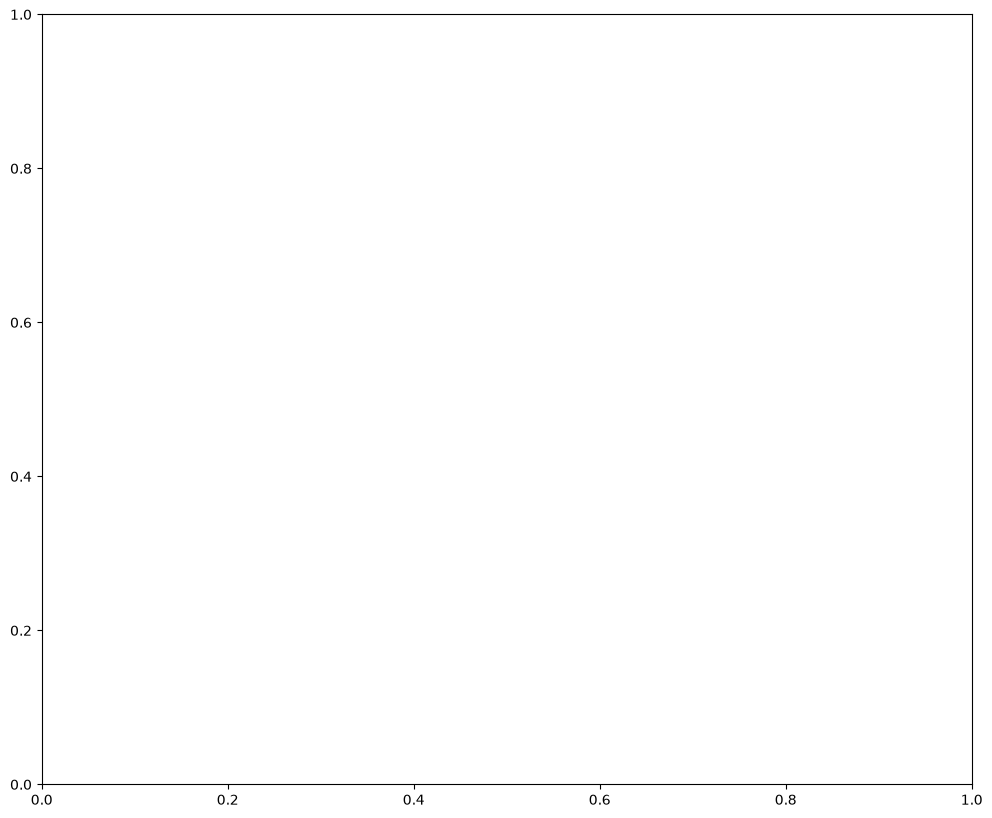

In [65]:
fig, ax = plt.subplots(figsize=(12, 10))

In [66]:
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".1f",
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .5},
    ax=ax
)

<Axes: >

In [67]:
plt.show()

In [68]:
print(corr.shape)
print(corr.columns)

(14, 14)
Index(['id', 'age', 'sex', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol',
       'gluc', 'smoke', 'alco', 'active', 'cardio', 'overweight'],
      dtype='str')


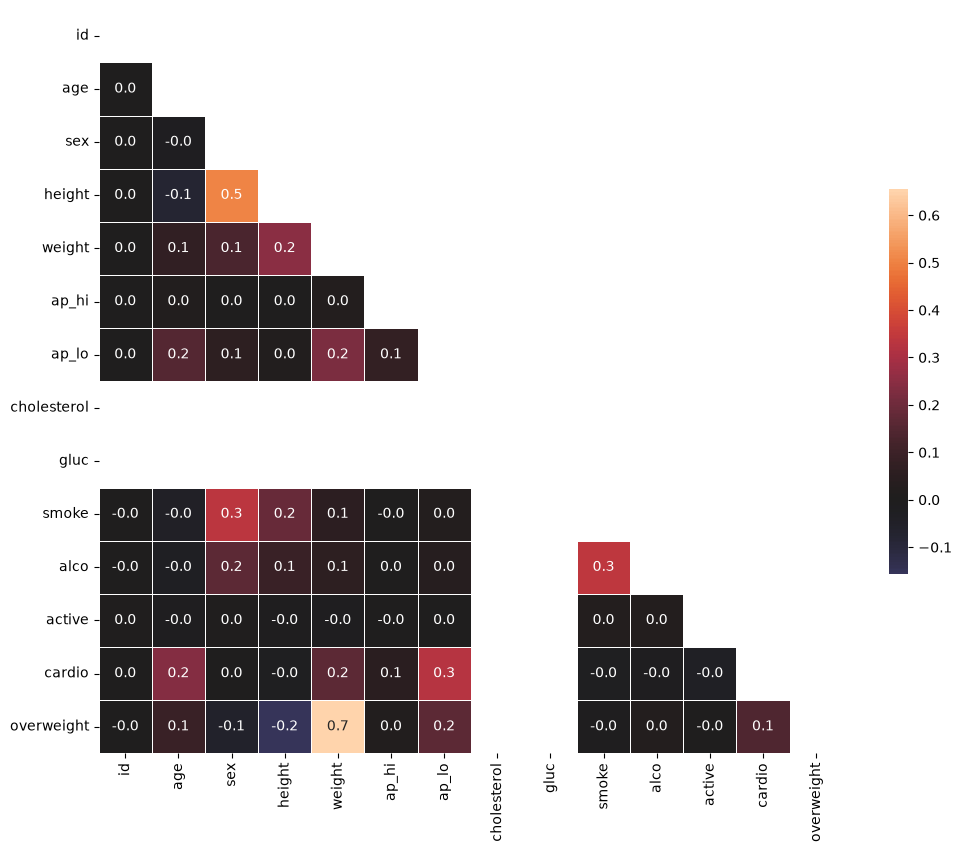

In [69]:
plt.close("all")

corr = df_heat.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".1f",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.5},
    ax=ax
)

plt.show()

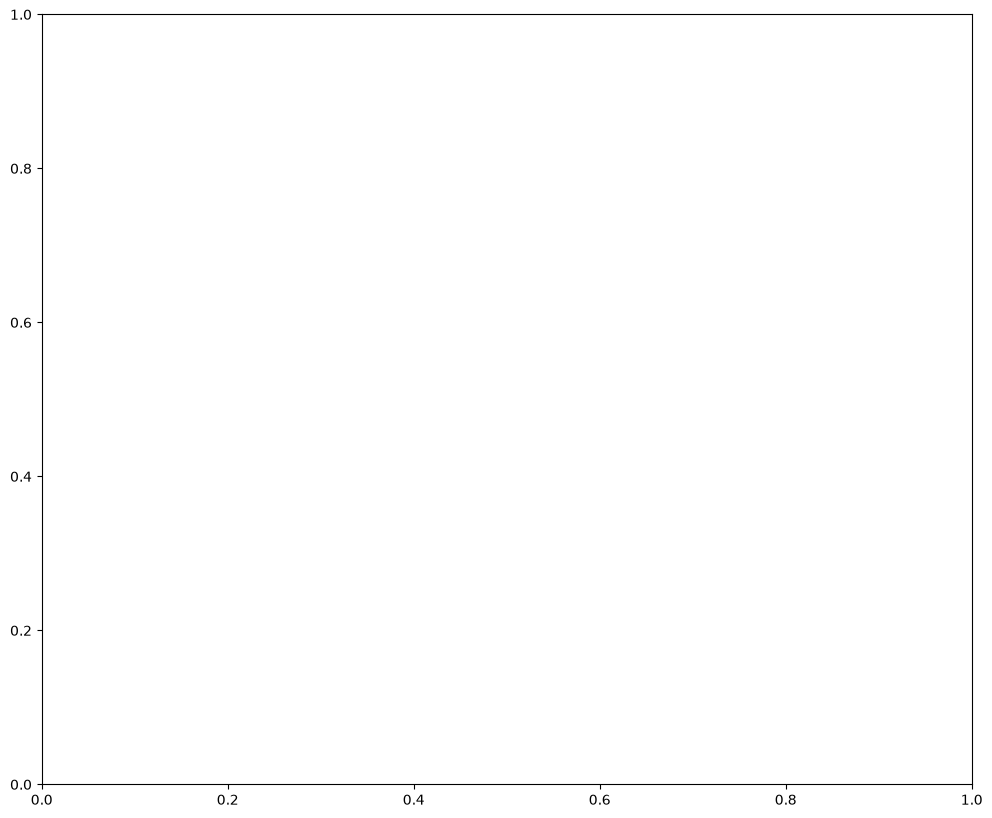

In [70]:
fig, ax = plt.subplots(figsize=(12, 10))

In [71]:
print(corr.shape)
print(corr.isna().sum().sum())
print(corr)

(14, 14)
52
                   id       age       sex    height    weight     ap_hi  \
id           1.000000  0.002623  0.003799  0.000221  0.000144  0.003489   
age          0.002623  1.000000 -0.018274 -0.077426  0.069705  0.018482   
sex          0.003799 -0.018274  1.000000  0.504722  0.130116  0.004941   
height       0.000221 -0.077426  0.504722  1.000000  0.248868  0.004300   
weight       0.000144  0.069705  0.130116  0.248868  1.000000  0.026527   
ap_hi        0.003489  0.018482  0.004941  0.004300  0.026527  1.000000   
ap_lo        0.000429  0.152787  0.059500  0.015356  0.223786  0.072260   
cholesterol       NaN       NaN       NaN       NaN       NaN       NaN   
gluc              NaN       NaN       NaN       NaN       NaN       NaN   
smoke       -0.002403 -0.044208  0.337682  0.187389  0.055805 -0.001978   
alco        -0.001039 -0.026956  0.169178  0.089257  0.058286  0.000607   
active       0.005890 -0.011471  0.007702 -0.005042 -0.012112 -0.000162   
cardio       

In [72]:
print(df["cholesterol"].value_counts())

cholesterol
0    70000
Name: count, dtype: int64


In [73]:
print(df["gluc"].value_counts())

gluc
0    70000
Name: count, dtype: int64


In [74]:
df = pd.read_csv("medical_examination.csv")

In [75]:
print(df["cholesterol"].value_counts())
print(df["gluc"].value_counts())

cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64
gluc
1    59479
3     5331
2     5190
Name: count, dtype: int64


In [76]:
df["cholesterol"] = (df["cholesterol"] > 1).astype(int)

In [77]:
df["cholesterol"].value_counts()

cholesterol
0    52385
1    17615
Name: count, dtype: int64

In [78]:
df["gluc"] = (df["gluc"] > 1).astype(int)

In [79]:
df["gluc"].value_counts()

gluc
0    59479
1    10521
Name: count, dtype: int64

In [80]:
print(df[["cholesterol", "gluc"]].value_counts())

cholesterol  gluc
0            0       48672
1            0       10807
             1        6808
0            1        3713
Name: count, dtype: int64


In [81]:
df_heat = df[
    (df["ap_lo"] <= df["ap_hi"]) &
    (df["height"] >= df["height"].quantile(0.025)) &
    (df["height"] <= df["height"].quantile(0.975)) &
    (df["weight"] >= df["weight"].quantile(0.025)) &
    (df["weight"] <= df["weight"].quantile(0.975))
]

In [82]:
df_heat.shape

(63259, 13)

In [83]:
corr = df_heat.corr()

In [84]:
print(corr[["cholesterol", "gluc"]])

             cholesterol      gluc
id              0.003719  0.002289
age             0.129996  0.086990
sex            -0.037605 -0.021357
height         -0.063522 -0.030469
weight          0.135981  0.107072
ap_hi           0.022807  0.011111
ap_lo           0.150362  0.074840
cholesterol     1.000000  0.383743
gluc            0.383743  1.000000
smoke           0.012680 -0.004157
alco            0.038446  0.014297
active          0.002494 -0.010145
cardio          0.203467  0.088445


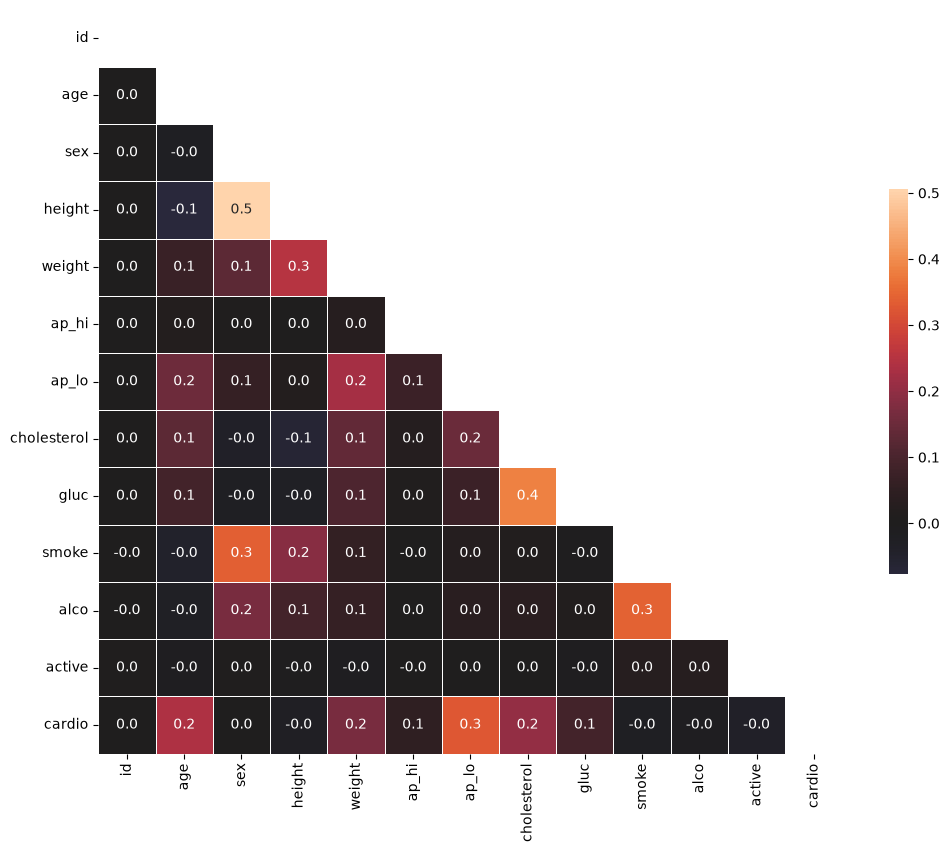

In [85]:
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".1f",
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .5},
    ax=ax
)

plt.show()

In [87]:
def draw_cat_plot():

    # Create overweight column
    df["overweight"] = (
        df["weight"] / ((df["height"] / 100) ** 2) > 25
    ).astype(int)

    # Normalize cholesterol
    df["cholesterol"] = (df["cholesterol"] > 1).astype(int)

    # Normalize glucose
    df["gluc"] = (df["gluc"] > 1).astype(int)

    # Create categorical DataFrame
    df_cat = pd.melt(
        df,
        id_vars=["cardio"],
        value_vars=[
            "cholesterol",
            "gluc",
            "smoke",
            "alco",
            "active",
            "overweight"
        ]
    )

    # Group and count
    df_cat = (
        df_cat
        .groupby(["cardio", "variable", "value"])
        .size()
        .reset_index(name="total")
    )

    # Create categorical plot
    fig = sns.catplot(
        x="variable",
        y="total",
        hue="value",
        col="cardio",
        data=df_cat,
        kind="bar"
    )

    return fig

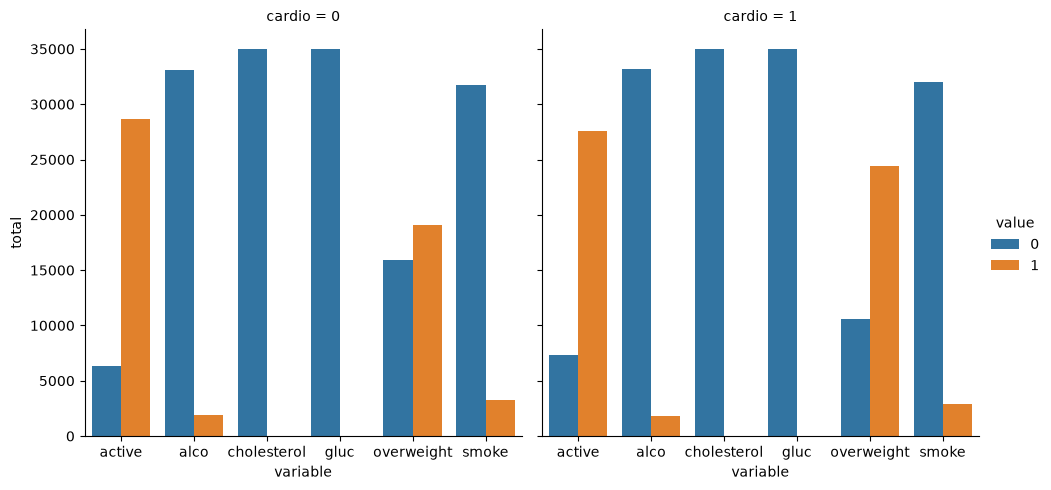

In [88]:
fig = draw_cat_plot()

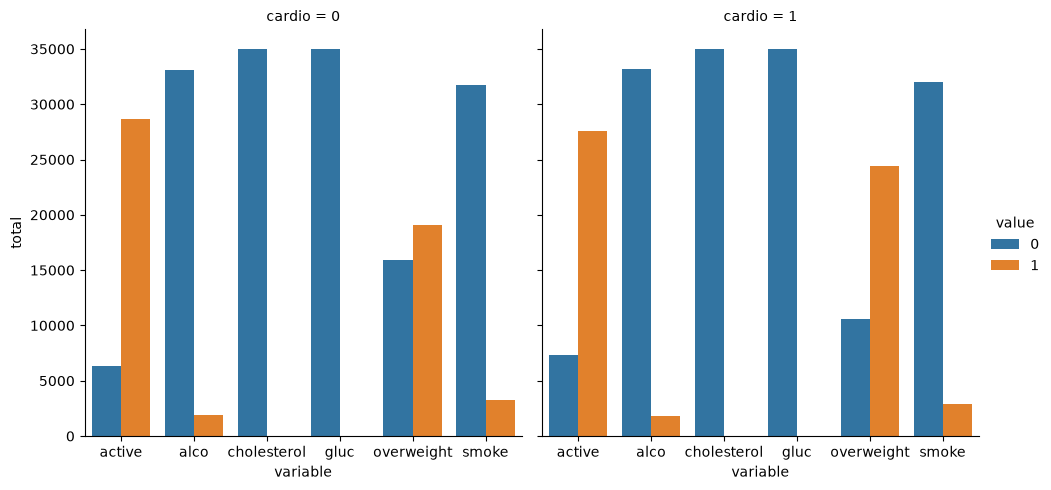

In [89]:
fig = draw_cat_plot()

In [90]:
plt.show()

In [92]:
def draw_heat_map():

    # Clean the data
    df_heat = df[
        (df["ap_lo"] <= df["ap_hi"]) &
        (df["height"] >= df["height"].quantile(0.025)) &
        (df["height"] <= df["height"].quantile(0.975)) &
        (df["weight"] >= df["weight"].quantile(0.025)) &
        (df["weight"] <= df["weight"].quantile(0.975))
    ]

    # Calculate correlation matrix
    corr = df_heat.corr()

    # Create mask for upper triangle
    mask = np.triu(np.ones_like(corr, dtype=bool))

    # Create figure
    fig, ax = plt.subplots(figsize=(12, 10))

    # Create heatmap
    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt=".1f",
        center=0,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.5},
        ax=ax
    )

    return fig

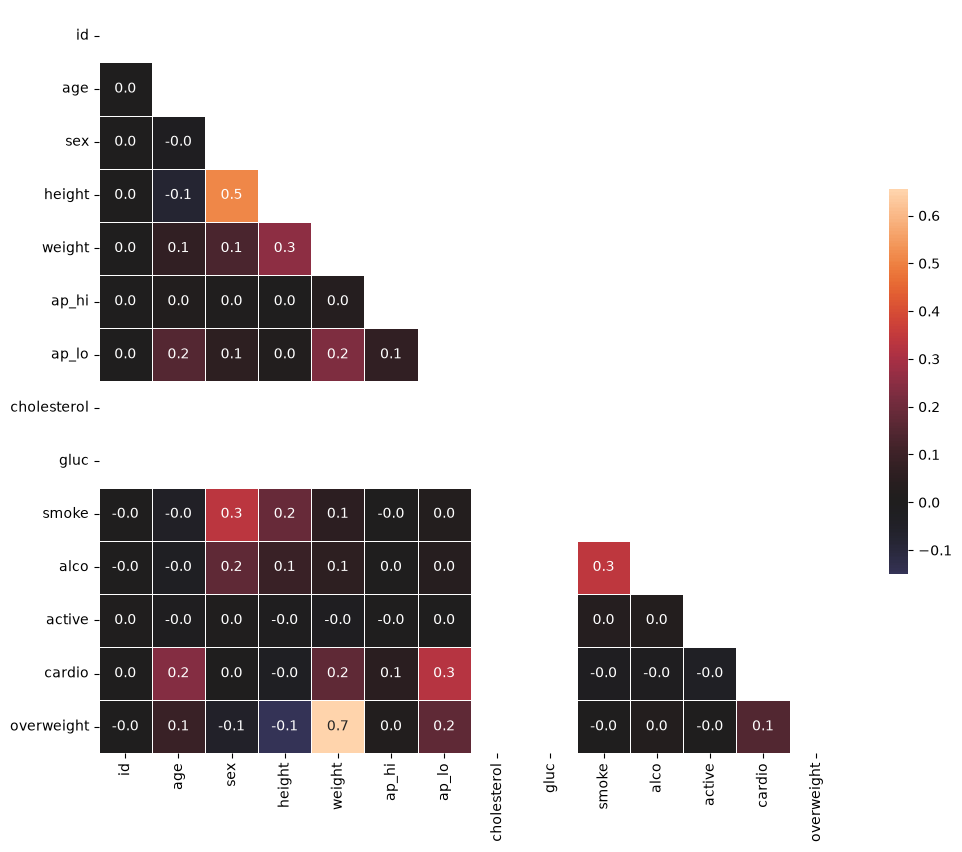

In [93]:
fig = draw_heat_map()

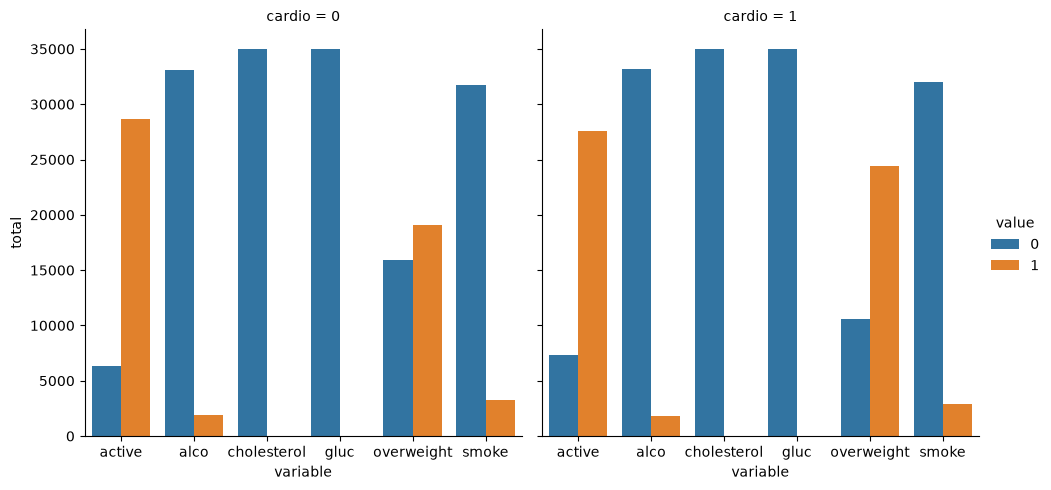

In [94]:
fig1 = draw_cat_plot()
plt.show()

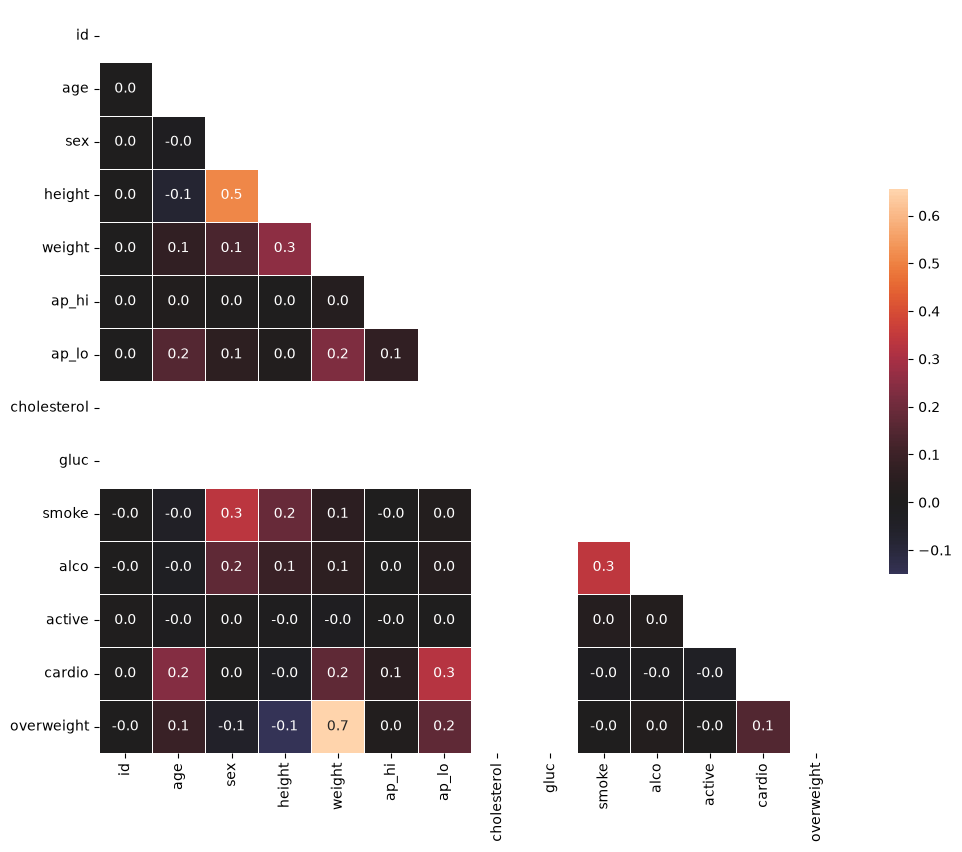

In [95]:
fig2 = draw_heat_map()
plt.show()